In [ ]:
%matplotlib widget

Задание 1  
Напишите программу, которая анимирует прорисовку сердца по параметрической кривой: сначала пустой экран, затем появляется точка, за ней тянется линия по контуру, через ~7 секунд сердце готово.  

План: что нужно сделать — по шагам  
Создайте массив t из 250 точек на отрезке [0, 2π].  
Вычислите массивы x и y по формулам ниже.  
Сделайте анимацию: 250 кадров, интервал 30 мс.  
Формулы:  
x(t) = 16·sin³(t)  
y(t) = 13·cos(t) − 5·cos(2t) − 2·cos(3t) − cos(4t)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


t = np.linspace(0, 2 * np.pi, 250)

x = 16*(np.sin(t)**3)
y = 13*np.cos(t) - 5*np.cos(2*t) - 2*np.cos(3*t) - np.cos(4*t)
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.axis('off')


[line]  = ax.plot([], [], 'r-', linewidth=2)   # пустая точка — заготовка
[dot]   = ax.plot([], [], 'ro', markersize=8)

def update(frame):
    n = frame + 1
    line.set_data(x[:n], y[:n])         # точка едет по горизонтали
    dot.set_data([x[n-1]], [y[n-1]])
    return line, dot

ani = FuncAnimation(fig, update, frames=250, interval=30, repeat=False)


plt.close(fig)
HTML(ani.to_jshtml())

Задание 2  
Напишите программу, которая анимирует «путь заблудившегося робота»: каждый кадр — один случайный шаг.  
За точкой тянется синий след, оси графика автоматически расширяются, чтобы след не вылезал за край.

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

plt.close('all') # удалить все старые выводы, на всякий случай

fig, ax = plt.subplots(figsize=(5, 5))

limits = [[-5.0, 5.0], [-5.0, 5.0]]
ax.set_xlim(*limits[0])
ax.set_ylim(*limits[1])
x = [random.uniform(-1.0, 1.0)]
y = [random.uniform(-1.0, 1.0)]

[line] = ax.plot([], [], 'b-', linewidth=1)
[dot]  = ax.plot([], [], 'ro', markersize=6)

def update(frame):
    x.append(x[-1] + random.uniform(-1.0, 1.0))
    y.append(y[-1] + random.uniform(-1.0, 1.0))
    if x[-1] < limits[0][0]:
        limits[0][0] = x[-1] - 1.0
        ax.set_xlim(*limits[0])
    if x[-1] > limits[0][1]:
        limits[0][1] = x[-1] + 1.0
        ax.set_xlim(*limits[0])
    if y[-1] < limits[1][0]:
        limits[1][0] = y[-1] - 1.0
        ax.set_ylim(*limits[1])
    if y[-1] > limits[1][1]:
        limits[1][1] = y[-1] + 1.0
        ax.set_ylim(*limits[1])

    line.set_data(x, y)
    dot.set_data([x[-1]], [y[-1]])

    return line, dot

ani = FuncAnimation(fig, update, frames=1000, interval=10, repeat=False)

plt.show()

Задание 3  
Вы продаёте лимонад. Выручка зависит от цены: R(x) = −2x² + 40x. Напишите программу, которая анимирует прорисовку параболы слева направо и останавливается ровно в вершине — точке максимальной выручки.

План: что нужно сделать — по шагам  
Создайте 400 точек x от 0 до 20, вычислите R = -2*x**2 + 40*x.  
Нарисуйте «тень» — всю параболу бледной: ax.plot(x, R, alpha=0.2).  
Найдите индекс вершины: peak_idx = int(np.argmax(R)).  
Создайте пустую красную линию, красную точку и ax.text(...) для цифр в углу.  

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(10, 5))

x = np.linspace(0, 20, 400)
R = -2*x**2 + 40*x

peak_idx = int(np.argmax(R))

ax.plot(x, R, alpha=0.2)

ax.set_xlim(0, 20)
ax.set_ylim(0, 220)

ax.grid(True, linestyle='--', alpha=0.6)

[line] = ax.plot([], [], 'r-', linewidth=2, label = f"цена = {x[0]} выручка = {R[0]}")
[dot]  = ax.plot([], [], 'ro', markersize=8)
ax.legend(loc='upper left')

def update(frame):
    line.set_data(x[:frame], R[:frame])         # точка едет по горизонтали
    line.set_label(f"цена = {x[frame]:.1f} выручка = {R[frame]:.1f}")
    ax.legend(loc='upper left')
    dot.set_data([x[frame-1]], [R[frame-1]])

    return line, dot

ani = FuncAnimation(fig, update, frames=peak_idx, interval=30, repeat=False)

plt.close(fig)
HTML(ani.to_jshtml())

Задание 4  
Известно: C(S) = 12/S — сколько чашек кофе нужно при S часах сна. Напишите программу, в которой бегунок едет по графику справа налево (сон тает с 8 ч до 2 ч), цвет маркера меняется (зелёный → оранжевый → красный), а в углу видны текущие цифры.  

План: что нужно сделать — по шагам  
Создайте S = np.linspace(2, 8, 400), C = 12 / S.  
Фигура: пределы, подписи, сетка, коричневая линия гиперболы.  
Вертикальная асимптота: ax.axvline(0, ls='--', color='red') + текст рядом.  
Создайте отдельный массив для анимации: S_anim = np.linspace(8, 2, 300) — обратный порядок!  

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

S = np.linspace(2, 8, 400)
C = 12 / S

l = len(S)

fig, ax = plt.subplots(figsize = (10, 5))

ax.set_xlim(0, 8.5)
ax.set_ylim(0, 7)

ax.grid(True, alpha = 0.2, linestyle='--', )
ax.plot(S, C, color="brown", alpha=0.2, lw=2)
ax.set_title("Сколько кофе нужно, чтобы выжить")

ax.set_xlabel("Часы сна S")
ax.set_ylabel("Чашки кофе C(S)")

ax.text(0.1, 6.3, 'S -> 0\nкофе -> ∞', color="red")
info = ax.text(6.3, 6.5, f"сон = {S[l-1]:.1f} ч     кофе = {C[l-1]:.1f}")

[line]  = ax.plot([], [], '-', color="brown", linewidth=2)
[dot]   = ax.plot([], [], 'go', markersize=10)

def update(frame):
    n = frame+1
    line.set_data([S[l-n:]], [C[l-n:]])
    dot.set_data([S[l-n-1]], [C[l-n-1]])
    info.set_text(f"сон = {S[l-n-1]:.1f} ч     кофе = {C[l-n-1]:.1f}")
    if int(C[l-n-1]) == 3:
        dot.set_color("orange")
    elif int(C[l-n-1]) == 5:
        dot.set_color("red")

    return line, dot

ani = FuncAnimation(fig, update, frames=400, interval=30, repeat=False)

plt.close()
HTML(ani.to_jshtml())

Задание 5  
Бактерия делится каждые 20 минут: N(t) = 2^(t/20). Напишите программу, которая строит две панели рядом (обычная шкала и логарифмическая) и останавливает анимацию ровно тогда, когда число бактерий достигает 1000.  

План: что нужно сделать — по шагам  
Посчитайте точку остановки: t_stop = 20 * np.log2(1000).  
Создайте t = np.linspace(0, t_stop, 400), N = 2 ** (t / 20).  
Создайте две панели: fig, (ax1, ax2) = plt.subplots(1, 2, ...).  
На левой — обычная шкала, на правой — ax2.set_yscale('log').  
На обеих — пределы, axhline(1000, ls='--', color='red'), бледная «тень» кривой.  
В update: показывайте t[:n], N[:n] на обеих панелях, точки — на t[n-1], N[n-1].  
На frame == last — маркеры красные, крупные, заголовок с ответом.  
Запуск: frames=len(t), repeat=False.  

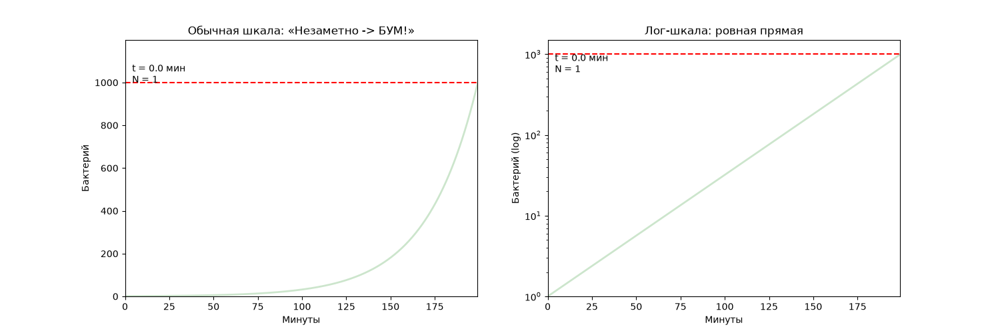

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

t_stop = 20 * np.log2(1000)
t = np.linspace(0, t_stop, 400)
N = 2**(t/20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15, 5))

ax1.set_title("Обычная шкала: «Незаметно -> БУМ!»")
ax2.set_title("Лог-шкала: ровная прямая")

ax2.set_yscale('log')

ax1.set_xlim(0, 199)
ax1.set_ylim(0, 1199)
ax2.set_xlim(0, 199)
ax2.set_ylim(1, 1500)

ax1.set_xlabel("Минуты")
ax2.set_xlabel("Минуты")

ax1.set_ylabel("Бактерий")
ax2.set_ylabel("Бактерий (log)")

for ax in (ax1, ax2):
    ax.axhline(1000, ls='--', color='red')
    ax.plot(t, N, color="green", alpha=0.2, lw=2)

info1 = ax1.text(4, 1000, f't = {t[0]} мин\nN = {int(N[0])}')
info2 = ax2.text(4, 600, f't = {t[0]} мин\nN = {int(N[0])}')

[line1]  = ax1.plot([], [], '-', color="green", linewidth=2)
[dot1]   = ax1.plot([], [], 'go', markersize=10)

[line2]  = ax2.plot([], [], '-', color="green", linewidth=2)
[dot2]   = ax2.plot([], [], 'go', markersize=10)

last = len(t) - 1

def update(frame):
    n = frame + 1
    for info in (info1, info2):
        info.set_text(f't = {t[n-1]:.1f} мин\nN = {int(N[n-1])}')
    for line in (line1, line2):
        line.set_data(t[:n], N[:n])
    for dot in (dot1, dot2):
        dot.set_data([t[n-1]], [N[n-1]])

    if frame == last:
        for dot in (dot1, dot2):
            dot.set_color("red")
            dot.set_markersize(15)
        ax1.set_title(f"Готово: {t[n-1]:.1f} мин ~ {round(t[n-1]//60)} ч {round(t[n-1])%60} мин")

    return line1, dot1, line2, dot2

ani = FuncAnimation(fig, update, frames=last+1, interval=10, repeat=False)

plt.show()

Задание 6  
Чай остывает по закону Ньютона: T(t) = 20 + 70·e^(−0.05t) (комната 20°C, старт 90°C).  
Напишите программу, которая анимирует остывание и останавливается ровно тогда, когда температура достигнет 40°C.

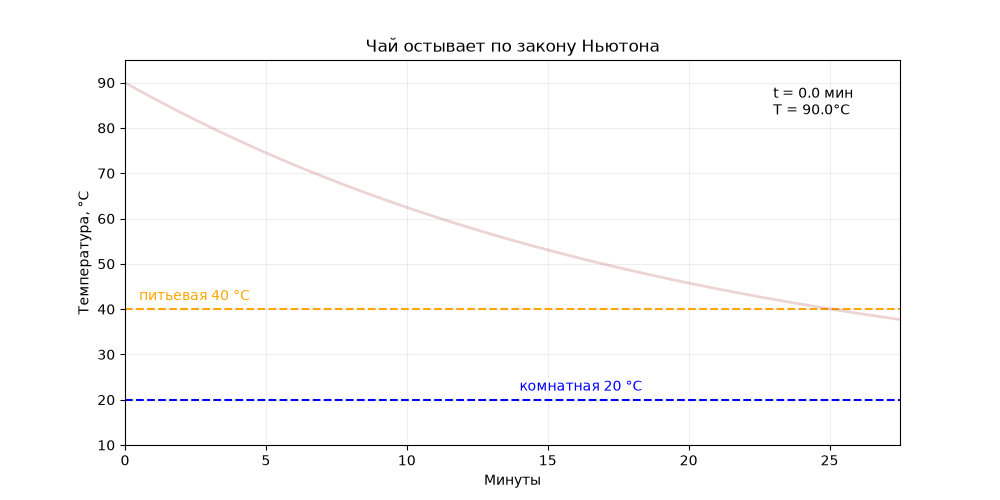

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

t = np.linspace(0, 30, 200)
T = 20 + 70 * np.e**(-0.05*t)

fig, ax = plt.subplots(figsize=(10, 5))

ax.set_title("Чай остывает по закону Ньютона")
ax.grid(True, alpha=0.2)

ax.set_xlim(0, 27.5)
ax.set_ylim(10, 95)
ax.set_yticks(np.arange(10, 95, 10))
ax.set_xlabel("Минуты")
ax.set_ylabel("Температура, °C")


ax.axhline(20, ls='--', color="blue")
ax.axhline(40, ls='--', color="orange")

ax.text(14, 22, "комнатная 20 °C", color="blue")
ax.text(0.5, 42, "питьевая 40 °C", color="orange")

ax.plot(t, T, ls='-', color="brown", alpha=0.2, lw=2)

[dot]   = ax.plot([], [], 'ro', ms=12)
[line]  = ax.plot([], [], 'r-', lw=2)

text = ax.text(23, 83, f"t = {t[0]:.1f} мин\nT = {T[0]:.1f}°C")

last = len(t)

def update(frame):
    n = frame + 1
    dot.set_data([t[n-1]], [T[n-1]])
    line.set_data(t[:n], T[:n])
    text.set_text(f"t = {t[n-1]:.1f} мин\nT = {T[n-1]:.1f}°C")

    if T[n] <= 40:
        ani.event_source.stop()

    return dot, line

ani = FuncAnimation(fig, update, frames=last, interval=30, repeat=False)

plt.show()